# 1. Đọc & Gộp dữ liệu thô

In [3]:
import glob
import pandas as pd

# 1. Tìm tất cả file Excel trong thư mục data/raw
files = sorted(glob.glob('../data/raw/CafeF_LichSuGia_HOSE_*.xlsx'))
print('Số file tìm thấy:', len(files))

# 2. Đọc và gộp 5 file thành 1 bảng duy nhất
dfs = []
for f in files:
  df_temp = pd.read_excel(f, sheet_name='LichSuGia')
  dfs.append(df_temp)

raw_df = pd.concat(dfs, ignore_index=True)

# 3. Xuất ra file .csv thô để nộp bài
raw_df.to_csv(
    '../data/processed/raw_data_nganhang.csv', index=False, encoding='utf-8-sig'
)

print('Tổng số dòng, cột:', raw_df.shape)
raw_df.head()

Số file tìm thấy: 5
Tổng số dòng, cột: (1230, 12)


,Mã,Ngày,Giá đóng cửa,Giá điều chỉnh,Thay đổi,Khối lượng khớp lệnh,Giá trị khớp lệnh,Khối lượng thỏa thuận,Giá trị thỏa thuận,Giá mở cửa,Giá cao nhất,Giá thấp nhất
0,ACB,16/11/2026,20.45,20.45,"+0,10 (+0,49%)",6816000,138.92,0,0.00,20.35,20.45,20.30
1,ACB,13/11/2026,20.35,20.35,"-0,05 (-0,25%)",10119400,206.02,4500000,96.75,20.35,20.50,20.30
2,ACB,12/11/2026,20.40,20.40,"-0,20 (-0,97%)",6199300,127.05,0,0.00,20.45,20.65,20.40
3,ACB,11/11/2026,20.60,20.60,"-0,10 (-0,48%)",9201400,188.76,2100000,40.53,20.70,20.70,20.35
4,ACB,10/11/2026,20.70,20.70,"+0,20 (+0,98%)",7797200,160.58,0,0.00,20.50,20.70,20.50


# 2. Kiểm tra & Thống kê mô tả dữ liệu

In [4]:
# 1. Xem kiểu dữ liệu từng cột
print("--- THÔNG TIN CÁC CỘT ---")
print(raw_df.info())

# 2. Kiểm tra dữ liệu khuyết thiếu (NaN) và trùng lặp
print("\n--- KIỂM TRA DỮ LIỆU BẨN ---")
print("Số ô trống từng cột:\n", raw_df.isnull().sum())
print("Số dòng trùng lặp (Mã + Ngày):", raw_df.duplicated(subset=['Mã', 'Ngày']).sum())

# 3. Kiểm tra ngày chia cổ tức (Giá đóng cửa khác Giá điều chỉnh)
so_dong_lech = (raw_df['Giá đóng cửa'] != raw_df['Giá điều chỉnh']).sum()
print(f"Số dòng Giá đóng cửa != Giá điều chỉnh: {so_dong_lech} dòng")

# 4. Thống kê mô tả theo từng mã ngân hàng (lấy số liệu đưa vào báo cáo)
print("\n--- THỐNG KÊ MÔ TẢ THEO MÃ ---")
thong_ke = raw_df.groupby('Mã')[['Giá đóng cửa', 'Khối lượng khớp lệnh']].agg(['count', 'mean', 'median', 'min', 'max', 'std'])
display(thong_ke)

--- THÔNG TIN CÁC CỘT ---
<class 'pandas.DataFrame'>
RangeIndex: 1230 entries, 0 to 1229
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Mã                     1230 non-null   str    
 1   Ngày                   1230 non-null   str    
 2   Giá đóng cửa           1230 non-null   float64
 3   Giá điều chỉnh         1230 non-null   float64
 4   Thay đổi               1230 non-null   str    
 5   Khối lượng khớp lệnh   1230 non-null   int64  
 6   Giá trị khớp lệnh      1230 non-null   float64
 7   Khối lượng thỏa thuận  1230 non-null   int64  
 8   Giá trị thỏa thuận     1230 non-null   float64
 9   Giá mở cửa             1230 non-null   float64
 10  Giá cao nhất           1230 non-null   float64
 11  Giá thấp nhất          1230 non-null   float64
dtypes: float64(7), int64(2), str(3)
memory usage: 115.4 KB
None

--- KIỂM TRA DỮ LIỆU BẨN ---
Số ô trống từng cột:
 Mã                       0
Ngày  

Giá đóng cửa                                            \
           count       mean  median    min   max       std   
Mã                                                           
ACB          246  23.053252  23.050  20.15  26.5  1.404537   
BID          246  39.980081  39.375  31.65  55.0  5.014596   
CTG          246  35.191057  34.150  28.75  52.0  5.361882   
MBB          246  23.937805  24.800  18.75  29.0  2.847651   
VCB          246  60.123984  59.400  53.20  76.0  4.151915   

    Khối lượng khớp lệnh                                                \
                   count          mean      median      min        max   
Mã                                                                       
ACB                  246  1.333348e+07  10690950.0  2754600   61171200   
BID                  246  5.826206e+06   4354200.0   878600   27506700   
CTG                  246  9.627244e+06   7722900.0  2739600   38922900   
MBB                  246  1.824706e+07  14067000.0  4549700  104577300   
VCB                  246  6.547158e+06   4789550.0  1581600   35200000   

                   
              std  
Mã                 
ACB  9.331091e+06  
BID  4.831238e+06  
CTG  6.118924e+06  
MBB  1.332802e+07  
VCB  5.571921e+06

# 3. Làm sạch & Tạo đặc trưng mới — Feature Engineering

In [5]:
df = raw_df.copy()

# 1. Chuyển cột Ngày sang định dạng thời gian và sắp xếp từ cũ -> mới theo từng mã
df['Ngày'] = pd.to_datetime(df['Ngày'], format='%d/%m/%Y')
df = (
    df.sort_values(['Mã', 'Ngày'])
    .drop_duplicates(subset=['Mã', 'Ngày'])
    .reset_index(drop=True)
)

# 2. Quy đổi giá Mở/Cao/Thấp về theo Giá điều chỉnh (xử lý 832 dòng chia cổ tức)
ty_le_dieu_chinh = df['Giá điều chỉnh'] / df['Giá đóng cửa']
df['Adj_Open'] = df['Giá mở cửa'] * ty_le_dieu_chinh
df['Adj_High'] = df['Giá cao nhất'] * ty_le_dieu_chinh
df['Adj_Low'] = df['Giá thấp nhất'] * ty_le_dieu_chinh
df['Adj_Close'] = df['Giá điều chỉnh']

# 3. Tạo đặc trưng mới (Feature Engineering) - dùng groupby('Mã') để không bị lẫn giữa các ngân hàng
df['Price_Range'] = df['Adj_High'] - df['Adj_Low']  # Biên độ dao động trong ngày
df['Return'] = df.groupby('Mã')['Adj_Close'].pct_change()  # Tỷ suất sinh lời ngày
df['MA5'] = df.groupby('Mã')['Adj_Close'].transform(
    lambda x: x.rolling(5).mean()
)  # Trung bình trượt 5 phiên
df['MA20'] = df.groupby('Mã')['Adj_Close'].transform(
    lambda x: x.rolling(20).mean()
)  # Trung bình trượt 20 phiên
df['Close_Lag1'] = df.groupby('Mã')['Adj_Close'].shift(1)  # Giá đóng cửa hôm qua
df['Close_Lag2'] = df.groupby('Mã')['Adj_Close'].shift(
    2
)  # Giá đóng cửa 2 ngày trước
df['Volume_Lag1'] = df.groupby('Mã')['Khối lượng khớp lệnh'].shift(
    1
)  # Khối lượng hôm qua

# 4. Tạo biến mục tiêu y: Giá đóng cửa điều chỉnh của phiên ngày mai (t+1)
df['Target_Close'] = df.groupby('Mã')['Adj_Close'].shift(-1)

# 5. Xóa các dòng NaN phát sinh ở đầu chuỗi (do tính MA20) và cuối chuỗi (do shift -1)
df_clean = (
    df.dropna().sort_values(['Ngày', 'Mã']).reset_index(drop=True)
)

# Xuất file dữ liệu sạch ra .csv
df_clean.to_csv(
    '../data/processed/clean_data_nganhang.csv', index=False, encoding='utf-8-sig'
)

print('Kích thước dữ liệu sau khi làm sạch:', df_clean.shape)
df_clean[[
    'Mã',
    'Ngày',
    'Adj_Close',
    'Price_Range',
    'Return',
    'MA5',
    'MA20',
    'Target_Close',
]].head(10)

Kích thước dữ liệu sau khi làm sạch: (1130, 24)


,Mã,Ngày,Adj_Close,Price_Range,Return,MA5,MA20,Target_Close
0,ACB,2025-12-12,20.25,0.517021,-0.018895,20.652,21.0125,20.29
1,BID,2025-12-12,34.23,0.647595,-0.016097,34.650,34.8140,34.23
2,CTG,2025-12-12,33.70,0.748889,-0.012020,34.218,33.8315,33.84
3,MBB,2025-12-12,19.22,0.760792,-0.034171,19.860,19.2080,19.02
4,VCB,2025-12-12,56.33,0.991725,-0.013831,57.222,57.9155,56.33
5,ACB,2025-12-15,20.29,0.129236,0.001975,20.540,20.9435,20.68
6,BID,2025-12-15,34.23,0.231284,0.000000,34.556,34.7490,34.60
7,CTG,2025-12-15,33.84,0.476620,0.004154,34.028,33.8605,34.73
8,MBB,2025-12-15,19.02,0.440463,-0.010406,19.612,19.2060,19.58
9,VCB,2025-12-15,56.33,0.595035,0.000000,57.004,57.7470,56.43


# 4. Khám phá dữ liệu bằng biểu đồ — EDA

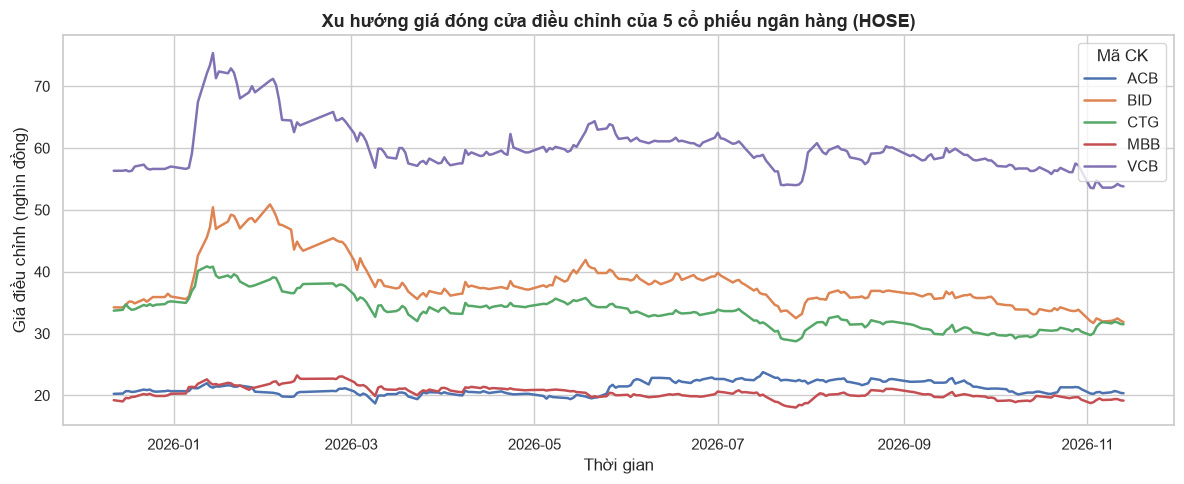

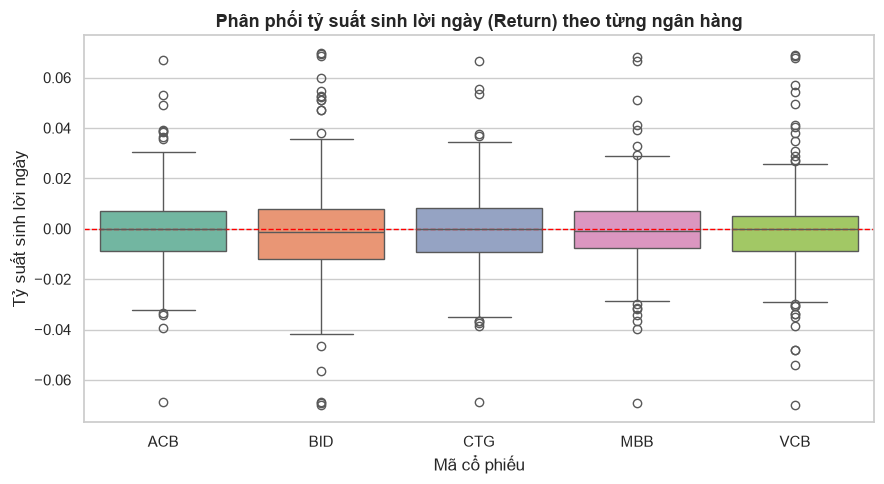

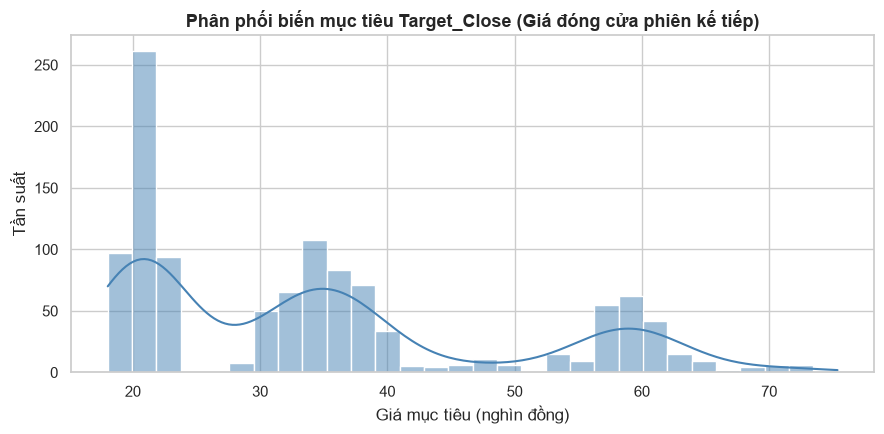

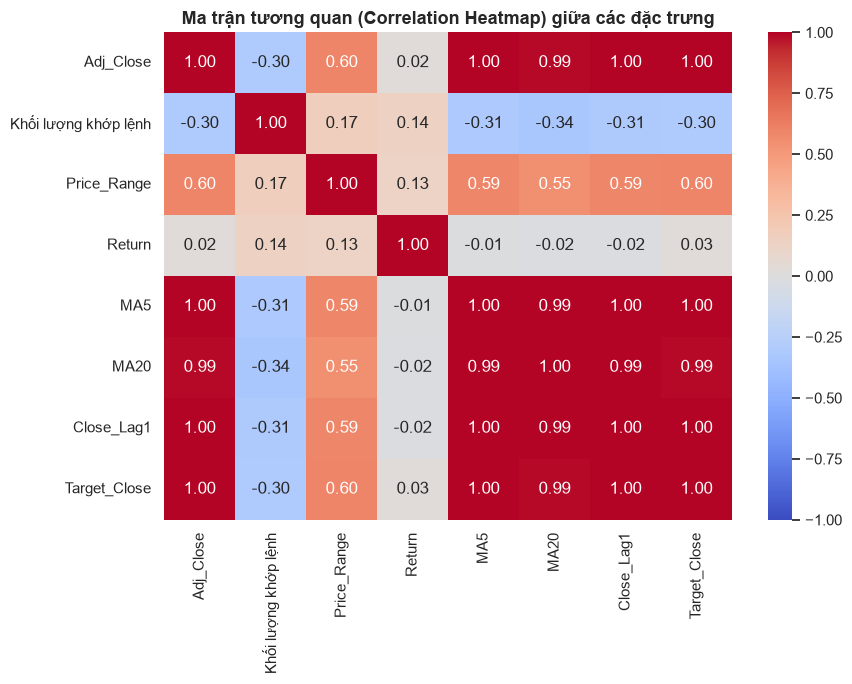

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

# 1. Biểu đồ chuỗi thời gian: Xu hướng biến động giá điều chỉnh của 5 ngân hàng
plt.figure(figsize=(12, 5))
for ma in df_clean['Mã'].unique():
  sub = df_clean[df_clean['Mã'] == ma]
  plt.plot(sub['Ngày'], sub['Adj_Close'], label=ma, linewidth=1.8)
plt.title(
    'Xu hướng giá đóng cửa điều chỉnh của 5 cổ phiếu ngân hàng (HOSE)',
    fontsize=13,
    fontweight='bold',
)
plt.xlabel('Thời gian')
plt.ylabel('Giá điều chỉnh (nghìn đồng)')
plt.legend(title='Mã CK')
plt.tight_layout()
plt.savefig('../reports/figures/1_xu_huong_gia.png', dpi=300)
plt.show()

# 2. Biểu đồ Boxplot: So sánh mức độ phân tán & ngoại lai của Tỷ suất sinh lời ngày
plt.figure(figsize=(9, 5))
sns.boxplot(data=df_clean, x='Mã', y='Return', hue='Mã', palette='Set2', legend=False)
plt.axhline(0, color='red', linestyle='--', linewidth=1)
plt.title(
    'Phân phối tỷ suất sinh lời ngày (Return) theo từng ngân hàng',
    fontsize=13,
    fontweight='bold',
)
plt.xlabel('Mã cổ phiếu')
plt.ylabel('Tỷ suất sinh lời ngày')
plt.tight_layout()
plt.savefig('../reports/figures/2_boxplot_return.png', dpi=300)
plt.show()

# 3. Biểu đồ Histogram + KDE: Phân phối biến mục tiêu Target_Close
plt.figure(figsize=(9, 4.5))
sns.histplot(
    df_clean['Target_Close'], bins=30, kde=True, color='steelblue'
)
plt.title(
    'Phân phối biến mục tiêu Target_Close (Giá đóng cửa phiên kế tiếp)',
    fontsize=13,
    fontweight='bold',
)
plt.xlabel('Giá mục tiêu (nghìn đồng)')
plt.ylabel('Tần suất')
plt.tight_layout()
plt.savefig('../reports/figures/3_phan_phoi_target.png', dpi=300)
plt.show()

# 4. Ma trận tương quan Heatmap giữa các biến số
cols_corr = [
    'Adj_Close',
    'Khối lượng khớp lệnh',
    'Price_Range',
    'Return',
    'MA5',
    'MA20',
    'Close_Lag1',
    'Target_Close',
]
plt.figure(figsize=(9, 7))
sns.heatmap(
    df_clean[cols_corr].corr(),
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
)
plt.title(
    'Ma trận tương quan (Correlation Heatmap) giữa các đặc trưng',
    fontsize=13,
    fontweight='bold',
)
plt.tight_layout()
plt.savefig('../reports/figures/4_heatmap_tuong_quan.png', dpi=300)
plt.show()

# 5. Chia tập dữ liệu chuẩn Chuỗi thời gian & Chuẩn hóa Scaling

In [7]:
from sklearn.preprocessing import StandardScaler

# 1. Chọn danh sách đặc trưng đầu vào (X) và biến mục tiêu (y)
feature_cols = [
    'Mã',
    'Adj_Open',
    'Adj_High',
    'Adj_Low',
    'Adj_Close',
    'Khối lượng khớp lệnh',
    'Price_Range',
    'Return',
    'MA5',
    'MA20',
    'Close_Lag1',
    'Close_Lag2',
    'Volume_Lag1',
]
target_col = 'Target_Close'

# Mã hóa One-Hot cho biến phân loại 'Mã' (tạo các cột Ma_ACB, Ma_BID, Ma_CTG, Ma_MBB, Ma_VCB)
df_model = pd.get_dummies(
    df_clean[['Ngày'] + feature_cols + [target_col]],
    columns=['Mã'],
    prefix='Ma',
    dtype=int,
)

# 2. Chia tập Train (70%) - Validation (15%) - Test (15%) THEO MỐC THỜI GIAN
unique_dates = sorted(df_model['Ngày'].unique())
n_dates = len(unique_dates)

train_end_date = unique_dates[int(n_dates * 0.70) - 1]
val_end_date = unique_dates[int(n_dates * 0.85) - 1]

train_df = df_model[df_model['Ngày'] <= train_end_date].copy()
val_df = df_model[
    (df_model['Ngày'] > train_end_date) & (df_model['Ngày'] <= val_end_date)
].copy()
test_df = df_model[df_model['Ngày'] > val_end_date].copy()

print(
    f"Tập Train : {train_df['Ngày'].min().date()} ->"
    f' {train_df["Ngày"].max().date()} | {len(train_df)} dòng'
)
print(
    f"Tập Val   : {val_df['Ngày'].min().date()} ->"
    f' {val_df["Ngày"].max().date()} | {len(val_df)} dòng'
)
print(
    f"Tập Test  : {test_df['Ngày'].min().date()} ->"
    f' {test_df["Ngày"].max().date()} | {len(test_df)} dòng'
)

# 3. Chuẩn hóa dữ liệu (StandardScaler) - CHỈ FIT TRÊN TẬP TRAIN
num_cols = [c for c in feature_cols if c != 'Mã']
scaler = StandardScaler()

X_train = train_df.drop(columns=['Ngày', target_col])
y_train = train_df[target_col]

X_val = val_df.drop(columns=['Ngày', target_col])
y_val = val_df[target_col]

X_test = test_df.drop(columns=['Ngày', target_col])
y_test = test_df[target_col]

X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_val[num_cols] = scaler.transform(X_val[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

print('\nKích thước X_train, X_val, X_test:', X_train.shape, X_val.shape, X_test.shape)
display(X_train.head(3))

Tập Train : 2025-12-12 -> 2026-08-06 | 790 dòng
Tập Val   : 2026-08-07 -> 2026-09-28 | 170 dòng
Tập Test  : 2026-09-29 -> 2026-11-13 | 170 dòng

Kích thước X_train, X_val, X_test: (790, 17) (170, 17) (170, 17)


,Adj_Open,Adj_High,Adj_Low,Adj_Close,Khối lượng khớp lệnh,Price_Range,Return,MA5,MA20,Close_Lag1,Close_Lag2,Volume_Lag1,Ma_ACB,Ma_BID,Ma_CTG,Ma_MBB,Ma_VCB
0,-0.969163,-0.979983,-0.986477,-0.999205,0.135138,-0.467539,-0.994815,-0.973806,-0.955917,-0.973401,-0.965411,-0.478282,1,0,0,0,0
1,-0.033549,-0.061493,-0.048696,-0.072641,-1.019908,-0.292789,-0.849256,-0.044549,-0.036268,-0.035421,-0.029329,-1.090890,0,1,0,0,0
2,-0.075389,-0.089399,-0.084249,-0.107769,-0.431532,-0.157224,-0.637236,-0.073227,-0.101736,-0.080497,-0.062477,-0.763149,0,0,1,0,0


# 6. Huấn luyện Baseline Model Linear Regression & Tính MSE, RMSE, MAE, R²

--- TẬP TRAIN (790 dòng) ---
MSE  : 0.5856
RMSE : 0.7653 (nghìn đồng)
MAE  : 0.4919 (nghìn đồng)
R2   : 0.9974

--- TẬP VALIDATION (170 dòng) ---
MSE  : 0.2354
RMSE : 0.4852 (nghìn đồng)
MAE  : 0.3659 (nghìn đồng)
R2   : 0.9988

--- TẬP TEST (170 dòng) ---
MSE  : 0.2936
RMSE : 0.5419 (nghìn đồng)
MAE  : 0.3915 (nghìn đồng)
R2   : 0.9983

=== KẾT QUẢ CHI TIẾT TRÊN TẬP TEST THEO TỪNG MÃ ===
Mã ACB: MSE = 0.0726 | RMSE = 0.2695 | MAE = 0.2024 | R2 = 0.4544
Mã BID: MSE = 0.4368 | RMSE = 0.6609 | MAE = 0.5664 | R2 = 0.6318
Mã CTG: MSE = 0.2083 | RMSE = 0.4564 | MAE = 0.3802 | R2 = 0.6613
Mã MBB: MSE = 0.0556 | RMSE = 0.2357 | MAE = 0.1814 | R2 = 0.4707
Mã VCB: MSE = 0.6948 | RMSE = 0.8335 | MAE = 0.6269 | R2 = 0.6684


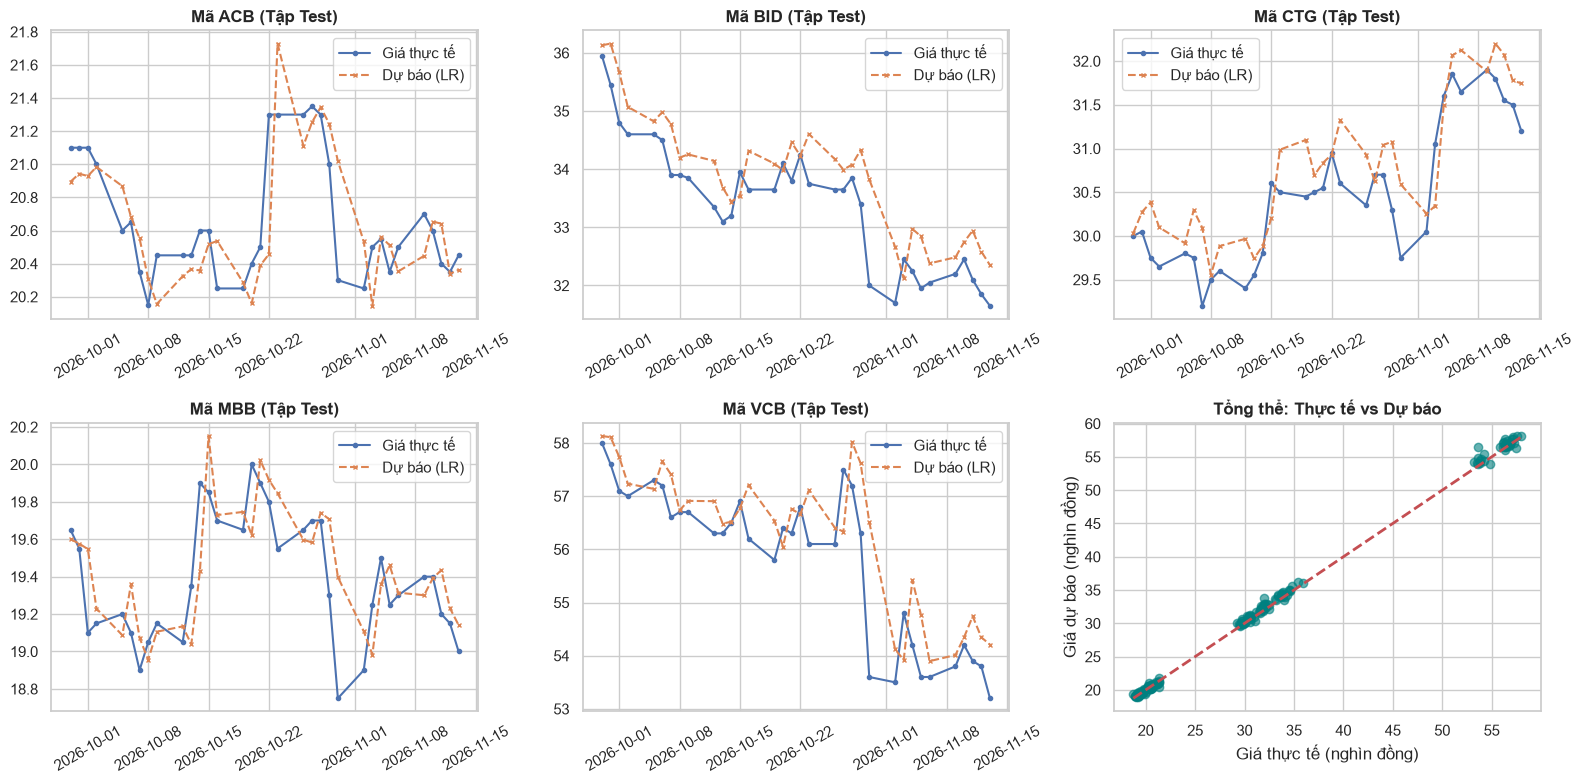

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 1. Khởi tạo và huấn luyện mô hình cơ sở (Baseline Model): Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# 2. Dự đoán trên cả 3 tập: Train, Validation và Test
y_train_pred = lr_model.predict(X_train)
y_val_pred = lr_model.predict(X_val)
y_test_pred = lr_model.predict(X_test)

# 3. Hàm tính toán các độ đo đánh giá hồi quy (MSE, RMSE, MAE, R2)
def evaluate_regression(y_true, y_pred, dataset_name):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"--- {dataset_name} ---")
    print(f"MSE  : {mse:.4f}")
    print(f"RMSE : {rmse:.4f} (nghìn đồng)")
    print(f"MAE  : {mae:.4f} (nghìn đồng)")
    print(f"R2   : {r2:.4f}\n")
    return mse, rmse, mae, r2

evaluate_regression(y_train, y_train_pred, "TẬP TRAIN (790 dòng)")
evaluate_regression(y_val, y_val_pred, "TẬP VALIDATION (170 dòng)")
evaluate_regression(y_test, y_test_pred, "TẬP TEST (170 dòng)")

# 4. Đánh giá chi tiết trên tập Test theo từng mã cổ phiếu (tránh ảo giác R2 gộp)
test_eval = test_df[['Ngày', 'Target_Close']].copy()
test_eval['Mã'] = df_clean.loc[test_df.index, 'Mã'].values
test_eval['Pred_Close'] = y_test_pred

print("=== KẾT QUẢ CHI TIẾT TRÊN TẬP TEST THEO TỪNG MÃ ===")
for ma, grp in test_eval.groupby('Mã'):
    m_mse = mean_squared_error(grp['Target_Close'], grp['Pred_Close'])
    m_rmse = np.sqrt(m_mse)
    m_mae = mean_absolute_error(grp['Target_Close'], grp['Pred_Close'])
    m_r2 = r2_score(grp['Target_Close'], grp['Pred_Close'])
    print(f"Mã {ma}: MSE = {m_mse:.4f} | RMSE = {m_rmse:.4f} | MAE = {m_mae:.4f} | R2 = {m_r2:.4f}")

# 5. Vẽ biểu đồ so sánh Giá thực tế vs Giá dự báo trên tập Test
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for idx, (ma, grp) in enumerate(test_eval.groupby('Mã')):
    axes[idx].plot(grp['Ngày'], grp['Target_Close'], label='Giá thực tế', marker='o', markersize=3)
    axes[idx].plot(grp['Ngày'], grp['Pred_Close'], label='Dự báo (LR)', linestyle='--', marker='x', markersize=3)
    axes[idx].set_title(f'Mã {ma} (Tập Test)', fontweight='bold')
    axes[idx].tick_params(axis='x', rotation=30)
    axes[idx].legend()

# Biểu đồ thứ 6: Scatter Plot đối chiếu tổng thể
axes[5].scatter(y_test, y_test_pred, alpha=0.6, color='teal')
axes[5].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[5].set_title('Tổng thể: Thực tế vs Dự báo', fontweight='bold')
axes[5].set_xlabel('Giá thực tế (nghìn đồng)')
axes[5].set_ylabel('Giá dự báo (nghìn đồng)')

plt.tight_layout()
plt.savefig('../reports/figures/5_ket_qua_baseline_lr.png', dpi=300)
plt.show()